# AI Cybersecurity Unit 1 Mini Project

## AI-Based Social Media Threat Analysis and Classification

In this notebook, I complete all four tasks of my AI in Cyber Security lab assignment in sequence.

### Tasks
1. Workspace Bootstrap and Environment Setup
2. Cyber Security Threat Landscape Analysis
3. Basic Machine Learning-Based Threat Classification
4. Introduction to Deep Learning

I use the provided social-media dataset. The README describes `BinaryNumTarget` as the binary truth value of the statement, where `1 = True` and `0 = False`. I use the related tweet text for the classification part.

For Task 3, I use **Random Forest**.
For Task 4, I use **MLPClassifier**, which is a basic feed-forward Artificial Neural Network available in Scikit-learn.

I keep the comments and explanations simple so I can explain each step during my lab or viva.

## Task 1 — Workspace Bootstrap and Environment Setup

I use Google Colab for this project. I install or import the basic Python libraries needed for data analysis, visualization, and machine learning.

In [ ]:
# I install the main libraries required for this project.
!pip -q install numpy pandas scikit-learn matplotlib seaborn

In [ ]:
# I import the libraries that I will use throughout the notebook.
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment setup completed successfully.")

Environment setup completed successfully.


### Load the dataset

I load the provided CSV file into a Pandas DataFrame. The expected file name is `Features_For_Traditional_ML_Techniques.csv`.

In [ ]:
# I load the provided dataset.
import pandas as pd

# locate the dataset automatically.

import pandas as pd

df = pd.read_csv("Features_For_Traditional_ML_Techniques.csv")

print(df.shape)
print(df["BinaryNumTarget"].value_counts(dropna=False))

(134198, 64)
BinaryNumTarget
1.0    68930
0.0    65268
Name: count, dtype: int64


## Task 2 — Cyber Security Threat Landscape Analysis

In this task, I first understand the dataset and then perform basic EDA and data cleaning. I look at the structure of the data, the target distribution, missing values, duplicate rows, and some social-media activity features.

In [ ]:
# I display the first few records so I can understand the dataset.
display(df.head())

,Unnamed: 0,majority_target,statement,BinaryNumTarget,tweet,followers_count,friends_count,favourites_count,statuses_count,listed_count,...,determiners,conjunctions,dots,exclamation,questions,ampersand,capitals,digits,long_word_freq,short_word_freq
0,0,True,End of eviction moratorium means millions of A...,1.0,@POTUS Biden Blunders - 6 Month Update\n\nInfl...,4262.0,3619.0,34945.0,16423.0,44.0,...,0,0,5,0,1,0,33,3,5,19
1,1,True,End of eviction moratorium means millions of A...,1.0,@S0SickRick @Stairmaster_ @6d6f636869 Not as m...,1393.0,1621.0,31436.0,37184.0,64.0,...,0,2,1,0,0,0,14,0,2,34
2,2,True,End of eviction moratorium means millions of A...,1.0,THE SUPREME COURT is siding with super rich pr...,9.0,84.0,219.0,1184.0,0.0,...,0,1,0,0,0,0,3,0,4,10
3,3,True,End of eviction moratorium means millions of A...,1.0,@POTUS Biden Blunders\n\nBroken campaign promi...,4262.0,3619.0,34945.0,16423.0,44.0,...,0,1,3,0,0,1,6,8,1,30
4,4,True,End of eviction moratorium means millions of A...,1.0,@OhComfy I agree. The confluence of events rig...,70.0,166.0,15282.0,2194.0,0.0,...,0,1,3,0,1,0,11,3,2,19


In [ ]:
# I check the data types and number of non-null values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134198 entries, 0 to 134197
Data columns (total 64 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Unnamed: 0              134198 non-null  int64  
 1   majority_target         134198 non-null  bool   
 2   statement               134198 non-null  object 
 3   BinaryNumTarget         134198 non-null  float64
 4   tweet                   134198 non-null  object 
 5   followers_count         134198 non-null  float64
 6   friends_count           134198 non-null  float64
 7   favourites_count        134198 non-null  float64
 8   statuses_count          134198 non-null  float64
 9   listed_count            134198 non-null  float64
 10  following               134198 non-null  float64
 11  embeddings              134198 non-null  object 
 12  BotScore                134198 non-null  float64
 13  BotScoreBinary          134198 non-null  float64
 14  cred                

In [ ]:
# I check the size of the dataset and the column names.
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (134198, 64)

Column names:
['Unnamed: 0', 'majority_target', 'statement', 'BinaryNumTarget', 'tweet', 'followers_count', 'friends_count', 'favourites_count', 'statuses_count', 'listed_count', 'following', 'embeddings', 'BotScore', 'BotScoreBinary', 'cred', 'normalize_influence', 'mentions', 'quotes', 'replies', 'retweets', 'favourites', 'hashtags', 'URLs', 'unique_count', 'total_count', 'ORG_percentage', 'NORP_percentage', 'GPE_percentage', 'PERSON_percentage', 'MONEY_percentage', 'DATE_percentage', 'CARDINAL_percentage', 'PERCENT_percentage', 'ORDINAL_percentage', 'FAC_percentage', 'LAW_percentage', 'PRODUCT_percentage', 'EVENT_percentage', 'TIME_percentage', 'LOC_percentage', 'WORK_OF_ART_percentage', 'QUANTITY_percentage', 'LANGUAGE_percentage', 'Word count', 'Max word length', 'Min word length', 'Average word length', 'present_verbs', 'past_verbs', 'adjectives', 'adverbs', 'adpositions', 'pronouns', 'TOs', 'determiners', 'conjunctions', 'dots', 'exclamation', 'quest

In [ ]:
# I check the basic statistical summary of numerical columns.
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,134198.0,67098.500000,38739.770050,0.0,33549.250000,67098.500000,100647.750000,1.341970e+05
BinaryNumTarget,134198.0,0.513644,0.499816,0.0,0.000000,1.000000,1.000000,1.000000e+00
followers_count,134198.0,11293.082103,437497.073676,0.0,70.000000,354.000000,1573.000000,1.306019e+08
friends_count,134198.0,1893.454455,6997.695671,0.0,168.000000,567.000000,1726.000000,5.869010e+05
favourites_count,134198.0,32981.233878,68780.210325,0.0,1356.000000,8377.000000,33526.500000,1.765080e+06
statuses_count,134198.0,34195.761449,75101.195265,1.0,3046.000000,11019.000000,33573.750000,2.958918e+06
listed_count,134198.0,73.300198,1083.274277,0.0,0.000000,2.000000,11.000000,2.221930e+05
following,134198.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000e+00
BotScore,134198.0,0.059106,0.167819,0.0,0.030000,0.030000,0.030000,1.000000e+00
BotScoreBinary,134198.0,0.032355,0.176942,0.0,0.000000,0.000000,0.000000,1.000000e+00


In [ ]:
# I check how many missing values are present in each column.
missing_values = df.isnull().sum().sort_values(ascending=False)

print("Total missing values:", int(missing_values.sum()))
display(missing_values[missing_values > 0].to_frame("Missing Values"))

Total missing values: 0


,Missing Values


In [ ]:
# I check for duplicate records.
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
# I check the distribution of the target variable.
# 1 = True and 0 = False according to the dataset README.
print("BinaryNumTarget distribution:")
print(df["BinaryNumTarget"].value_counts(dropna=False))

target_percent = (
    df["BinaryNumTarget"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("\nTarget distribution in percentage:")
print(target_percent)

BinaryNumTarget distribution:
BinaryNumTarget
1.0    68930
0.0    65268
Name: count, dtype: int64

Target distribution in percentage:
BinaryNumTarget
1.0    51.36
0.0    48.64
Name: proportion, dtype: float64


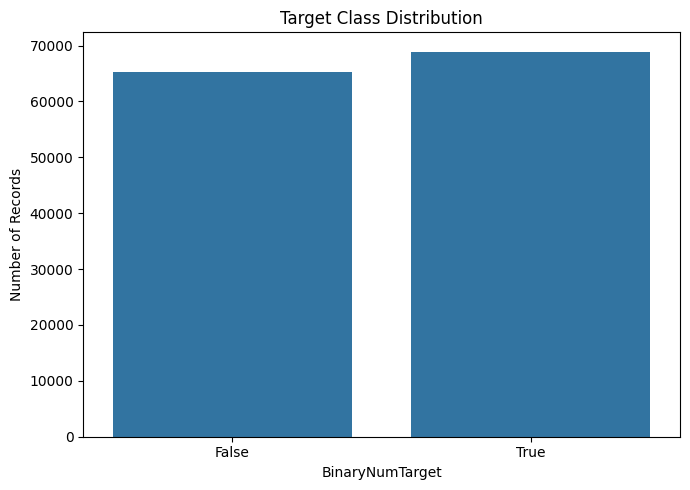

In [ ]:
# I visualize the two target classes.
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="BinaryNumTarget"
)

plt.title("Target Class Distribution")
plt.xlabel("BinaryNumTarget")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["False", "True"])
plt.tight_layout()
plt.show()

### Activity feature analysis

I compare some social-media activity features between the two target classes. These plots help me understand whether user activity changes across the classes.

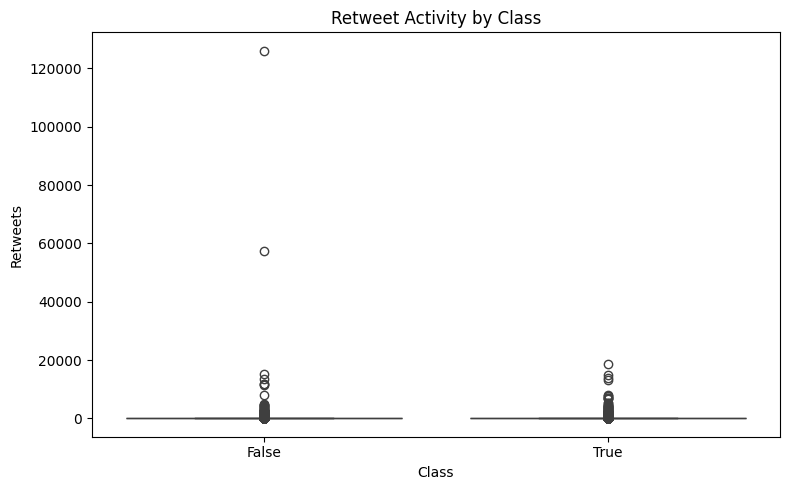

In [ ]:
# I compare retweet activity between the two classes.
if "retweets" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=df,
        x="BinaryNumTarget",
        y="retweets"
    )
    plt.title("Retweet Activity by Class")
    plt.xlabel("Class")
    plt.ylabel("Retweets")
    plt.xticks([0, 1], ["False", "True"])
    plt.tight_layout()
    plt.show()

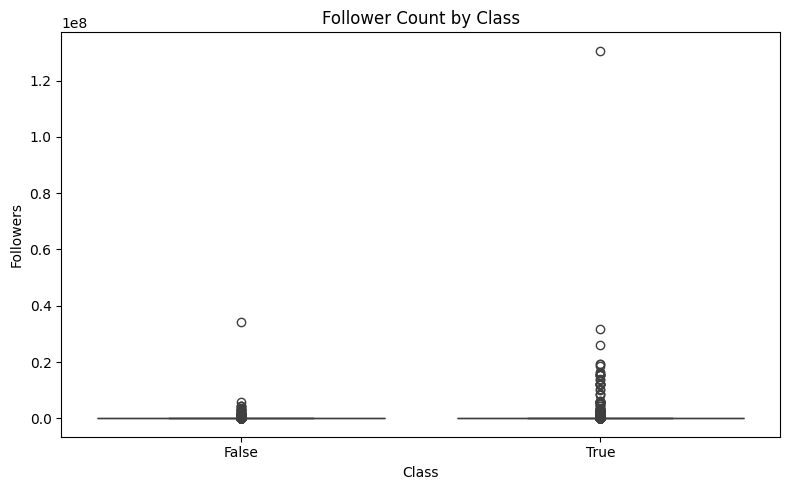

In [ ]:
# I compare follower counts between the two classes.
if "followers_count" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=df,
        x="BinaryNumTarget",
        y="followers_count"
    )
    plt.title("Follower Count by Class")
    plt.xlabel("Class")
    plt.ylabel("Followers")
    plt.xticks([0, 1], ["False", "True"])
    plt.tight_layout()
    plt.show()

In [ ]:
# I compare a few activity features using their class-wise average.
activity_features = [
    "mentions",
    "quotes",
    "replies",
    "retweets",
    "favourites",
    "hashtags",
    "URLs"
]

available_activity = [
    col for col in activity_features
    if col in df.columns
]

if available_activity:
    activity_summary = (
        df.groupby("BinaryNumTarget")[available_activity]
        .mean()
        .rename(index={0: "False", 1: "True"})
    )

    display(activity_summary)

,mentions,quotes,replies,retweets,favourites,hashtags,URLs
BinaryNumTarget,,,,,,,
False,1.463152,0.791705,2.576194,7.857618,34.654455,0.054897,0.799350
True,1.318628,0.366705,1.287378,5.553953,20.866560,0.151908,0.679327


### Data cleaning

I clean the data before model training. I remove duplicate rows, handle missing target values, convert the target to integer form, and keep the original tweet and statement columns because I need them later for text classification.

I do not use target-related columns as model features because that could cause data leakage.

In [ ]:
# I remove exact duplicate rows.
before_duplicates = len(df)

df = df.drop_duplicates().reset_index(drop=True)

after_duplicates = len(df)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates :", after_duplicates)
print("Duplicates removed              :", before_duplicates - after_duplicates)

Rows before removing duplicates: 134198
Rows after removing duplicates : 134198
Duplicates removed              : 0


In [ ]:
# I remove rows where the target value is missing.
df = df.dropna(subset=["BinaryNumTarget"]).copy()

# I make sure the target is stored as an integer.
df["BinaryNumTarget"] = df["BinaryNumTarget"].astype(int)

print("Target values after cleaning:")
print(df["BinaryNumTarget"].value_counts())

Target values after cleaning:
BinaryNumTarget
1    68930
0    65268
Name: count, dtype: int64


In [ ]:
# I fill missing tweet text with an empty string because the text model needs a valid string.
df["tweet"] = df["tweet"].fillna("").astype(str)

# I fill missing statement text with an empty string because it is used to create
# a statement-level train/test split.
df["statement"] = df["statement"].fillna("").astype(str)

print("Data cleaning completed.")
print("Final dataset shape:", df.shape)

Data cleaning completed.
Final dataset shape: (134198, 64)


### My observation from Task 2

From the EDA, I can see the class distribution and how social-media activity features differ between the two classes. I also checked missing values and duplicate records before moving to model training.

For the classification stage, I use the tweet text because it is directly related to the social-media content in the dataset.

## Task 3 — Basic Machine Learning-Based Threat Classification

I use **Random Forest** as my traditional machine-learning model.

Instead of randomly splitting individual tweets, I split by `statement`. This is important because several tweets can be related to the same statement. Keeping the same statement in only one side of the split reduces the chance of information leakage.

I convert tweet text into TF-IDF features and then reduce the feature size using TruncatedSVD before training Random Forest.

In [ ]:
from sklearn.model_selection import train_test_split

# I first create one label for each unique statement.
# This helps me keep tweets from the same statement in the same split.

statement_labels = (
    df.groupby("statement")["BinaryNumTarget"]
    .first()
    .reset_index()
)

print("Unique statements:", len(statement_labels))

# I split the statements into training and testing groups.

rf_train_statements, rf_test_statements = train_test_split(
    statement_labels,
    test_size=0.20,
    random_state=42,
    stratify=statement_labels["BinaryNumTarget"]
)

# I create sets of training and testing statements.

rf_train_statement_set = set(
    rf_train_statements["statement"]
)

rf_test_statement_set = set(
    rf_test_statements["statement"]
)

# I create the final training and testing data.

rf_train_df = df[
    df["statement"].isin(rf_train_statement_set)
].copy()

rf_test_df = df[
    df["statement"].isin(rf_test_statement_set)
].copy()

print("Training rows:", len(rf_train_df))
print("Testing rows :", len(rf_test_df))

print("\nTraining target:")
print(rf_train_df["BinaryNumTarget"].value_counts())

print("\nTesting target:")
print(rf_test_df["BinaryNumTarget"].value_counts())

# I check that the same statement is not present in both datasets.

overlap = (
    rf_train_statement_set &
    rf_test_statement_set
)

print("\nOverlapping statements:", len(overlap))

Unique statements: 1058
Training rows: 109923
Testing rows : 24275

Training target:
BinaryNumTarget
1    56188
0    53735
Name: count, dtype: int64

Testing target:
BinaryNumTarget
1    12742
0    11533
Name: count, dtype: int64

Overlapping statements: 0


In [ ]:
# I separate tweet text and target values.

rf_train_text = (
    rf_train_df["tweet"]
    .fillna("")
    .astype(str)
)

rf_test_text = (
    rf_test_df["tweet"]
    .fillna("")
    .astype(str)
)

rf_y_train = (
    rf_train_df["BinaryNumTarget"]
    .astype(int)
)

rf_y_test = (
    rf_test_df["BinaryNumTarget"]
    .astype(int)
)

print("Training text:", len(rf_train_text))
print("Testing text :", len(rf_test_text))

print("\nTraining classes:")
print(rf_y_train.value_counts())

print("\nTesting classes:")
print(rf_y_test.value_counts())

Training text: 109923
Testing text : 24275

Training classes:
BinaryNumTarget
1    56188
0    53735
Name: count, dtype: int64

Testing classes:
BinaryNumTarget
1    12742
0    11533
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# I convert the tweet text into numerical TF-IDF features.

rf_tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3,
    sublinear_tf=True,
    stop_words="english"
)

# I fit TF-IDF only on training text.
# The testing text is transformed using the already fitted vectorizer.

rf_train_tfidf = rf_tfidf.fit_transform(
    rf_train_text
)

rf_test_tfidf = rf_tfidf.transform(
    rf_test_text
)

print("TF-IDF training shape:", rf_train_tfidf.shape)
print("TF-IDF testing shape :", rf_test_tfidf.shape)

TF-IDF training shape: (109923, 5000)
TF-IDF testing shape : (24275, 5000)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# I separate the tweet text and target values for training and testing.
text_train = rf_train_df["tweet"].fillna("").astype(str)
text_test = rf_test_df["tweet"].fillna("").astype(str)

y_train = rf_train_df["BinaryNumTarget"].astype(int)
y_test = rf_test_df["BinaryNumTarget"].astype(int)

# I convert the tweet text into numerical TF-IDF features.
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3,
    sublinear_tf=True,
    stop_words="english"
)

# I fit TF-IDF only on the training data to avoid test-data leakage.
X_train_tfidf = tfidf.fit_transform(text_train)
X_test_tfidf = tfidf.transform(text_test)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape :", X_test_tfidf.shape)

TF-IDF training shape: (109923, 5000)
TF-IDF testing shape : (24275, 5000)


In [ ]:
from sklearn.decomposition import TruncatedSVD

# I reduce the 5000 TF-IDF features to 50 components.
# This makes the data smaller and easier for the models to process.

rf_svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

rf_train_features = rf_svd.fit_transform(
    rf_train_tfidf
)

rf_test_features = rf_svd.transform(
    rf_test_tfidf
)

print("SVD training shape:", rf_train_features.shape)
print("SVD testing shape :", rf_test_features.shape)

print(
    "Explained variance:",
    round(
        rf_svd.explained_variance_ratio_.sum(),
        4
    )
)

SVD training shape: (109923, 50)
SVD testing shape : (24275, 50)
Explained variance: 0.1267


In [ ]:
from sklearn.decomposition import TruncatedSVD

# Redefining SVD using the newly computed TF-IDF features from cell It3bdKFEiS3T
svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

print("SVD training shape:", X_train_svd.shape)
print("SVD testing shape :", X_test_svd.shape)

print(
    "Explained variance:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

SVD training shape: (109923, 50)
SVD testing shape : (24275, 50)
Explained variance: 0.1267


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# I train my Random Forest classifier.

rf_model_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_start = time.time()

rf_model_final.fit(
    rf_train_features,
    rf_y_train
)

rf_train_time = time.time() - rf_start

print(
    "Random Forest training completed in",
    round(rf_train_time, 2),
    "seconds."
)

print(
    "Classes learned by Random Forest:",
    rf_model_final.classes_
)

Random Forest training completed in 122.38 seconds.
Classes learned by Random Forest: [0 1]


In [ ]:
# I use the trained Random Forest to predict the unseen test data.

rf_pred_final = rf_model_final.predict(
    rf_test_features
)

# I first check that the model learned both classes.

if len(rf_model_final.classes_) != 2:
    raise ValueError(
        f"Random Forest learned only these classes: "
        f"{rf_model_final.classes_}. "
        f"Both classes [0, 1] are required."
    )

# I get the probability of class 1 for ROC-AUC.

rf_prob_final = rf_model_final.predict_proba(
    rf_test_features
)[:, 1]

print("Random Forest prediction completed.")

Random Forest prediction completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

rf_accuracy_final = accuracy_score(
    rf_y_test,
    rf_pred_final
)

rf_precision_final = precision_score(
    rf_y_test,
    rf_pred_final,
    zero_division=0
)

rf_recall_final = recall_score(
    rf_y_test,
    rf_pred_final,
    zero_division=0
)

rf_f1_final = f1_score(
    rf_y_test,
    rf_pred_final,
    zero_division=0
)

rf_auc_final = roc_auc_score(
    rf_y_test,
    rf_prob_final
)

rf_pr_auc_final = average_precision_score(
    rf_y_test,
    rf_prob_final
)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {rf_accuracy_final:.4f}")
print(f"Precision: {rf_precision_final:.4f}")
print(f"Recall   : {rf_recall_final:.4f}")
print(f"F1-score : {rf_f1_final:.4f}")
print(f"ROC-AUC  : {rf_auc_final:.4f}")
print(f"PR-AUC   : {rf_pr_auc_final:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        rf_y_test,
        rf_pred_final,
        target_names=["False", "True"],
        zero_division=0
    )
)

Random Forest Results
---------------------
Accuracy : 0.7872
Precision: 0.7517
Recall   : 0.8879
F1-score : 0.8141
ROC-AUC  : 0.8528
PR-AUC   : 0.8447

Classification Report:
              precision    recall  f1-score   support

       False       0.85      0.68      0.75     11533
        True       0.75      0.89      0.81     12742

    accuracy                           0.79     24275
   macro avg       0.80      0.78      0.78     24275
weighted avg       0.80      0.79      0.78     24275



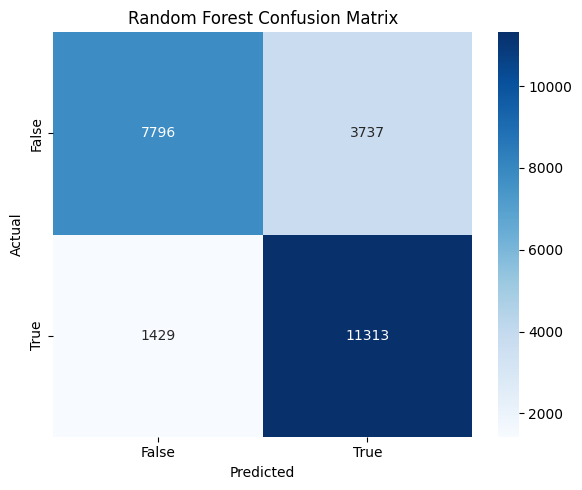

In [ ]:
# I visualize the Random Forest confusion matrix.

rf_cm = confusion_matrix(
    rf_y_test,
    rf_pred_final
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["False", "True"],
    yticklabels=["False", "True"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

## Task 4 — Introduction to Deep Learning

For the deep-learning part, I use **MLPClassifier** from Scikit-learn.

MLP stands for Multi-Layer Perceptron. It is a basic feed-forward neural network, so it satisfies the lab requirement for a basic neural-network model.

I use the same TF-IDF/SVD representation and the same train/test data as Random Forest. Before training the MLP, I scale the features because neural networks generally work better when numerical inputs are on a similar scale.

In [ ]:
from sklearn.preprocessing import StandardScaler

# I use the same SVD features for my neural network.
# I scale them because neural networks usually work better
# when numerical inputs are on a similar scale.

mlp_scaler_final = StandardScaler()

mlp_train_features = mlp_scaler_final.fit_transform(
    rf_train_features
)

mlp_test_features = mlp_scaler_final.transform(
    rf_test_features
)

print(
    "MLP training shape:",
    mlp_train_features.shape
)

print(
    "MLP testing shape:",
    mlp_test_features.shape
)

MLP training shape: (109923, 50)
MLP testing shape: (24275, 50)


In [ ]:
from sklearn.neural_network import MLPClassifier

# I use a simple MLP with two hidden layers.
# This is the basic neural-network model.

mlp_model_final = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.20,
    n_iter_no_change=3,
    random_state=42
)

mlp_start = time.time()

mlp_model_final.fit(
    mlp_train_features,
    rf_y_train
)

mlp_train_time = time.time() - mlp_start

print(
    "MLPClassifier training completed in",
    round(mlp_train_time, 2),
    "seconds."
)

print(
    "Iterations used:",
    mlp_model_final.n_iter_
)

print(
    "Classes learned by MLP:",
    mlp_model_final.classes_
)

MLPClassifier training completed in 17.15 seconds.
Iterations used: 27
Classes learned by MLP: [0 1]


In [ ]:
# I generate predictions from my trained MLP.

mlp_pred_final = mlp_model_final.predict(
    mlp_test_features
)

# I check that the MLP learned both classes.

if len(mlp_model_final.classes_) != 2:
    raise ValueError(
        f"MLP learned only these classes: "
        f"{mlp_model_final.classes_}. "
        f"Both classes [0, 1] are required."
    )

mlp_prob_final = mlp_model_final.predict_proba(
    mlp_test_features
)[:, 1]

print("MLP prediction completed.")

MLP prediction completed.


In [ ]:
mlp_accuracy_final = accuracy_score(
    rf_y_test,
    mlp_pred_final
)

mlp_precision_final = precision_score(
    rf_y_test,
    mlp_pred_final,
    zero_division=0
)

mlp_recall_final = recall_score(
    rf_y_test,
    mlp_pred_final,
    zero_division=0
)

mlp_f1_final = f1_score(
    rf_y_test,
    mlp_pred_final,
    zero_division=0
)

mlp_auc_final = roc_auc_score(
    rf_y_test,
    mlp_prob_final
)

mlp_pr_auc_final = average_precision_score(
    rf_y_test,
    mlp_prob_final
)

print("MLPClassifier Results")
print("---------------------")
print(f"Accuracy : {mlp_accuracy_final:.4f}")
print(f"Precision: {mlp_precision_final:.4f}")
print(f"Recall   : {mlp_recall_final:.4f}")
print(f"F1-score : {mlp_f1_final:.4f}")
print(f"ROC-AUC  : {mlp_auc_final:.4f}")
print(f"PR-AUC   : {mlp_pr_auc_final:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        rf_y_test,
        mlp_pred_final,
        target_names=["False", "True"],
        zero_division=0
    )
)

MLPClassifier Results
---------------------
Accuracy : 0.7322
Precision: 0.7468
Recall   : 0.7410
F1-score : 0.7439
ROC-AUC  : 0.8157
PR-AUC   : 0.8190

Classification Report:
              precision    recall  f1-score   support

       False       0.72      0.72      0.72     11533
        True       0.75      0.74      0.74     12742

    accuracy                           0.73     24275
   macro avg       0.73      0.73      0.73     24275
weighted avg       0.73      0.73      0.73     24275



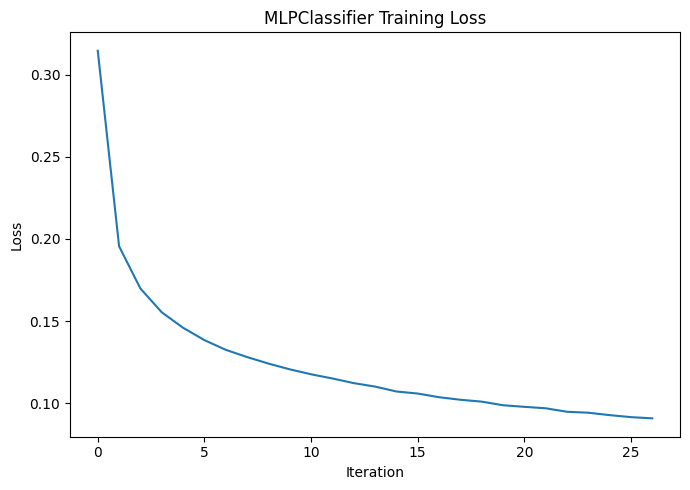

In [ ]:
# I plot the training loss to see how the MLP learned over the iterations.

plt.figure(figsize=(7, 5))

plt.plot(
    mlp_model_final.loss_curve_
)

plt.title("MLPClassifier Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

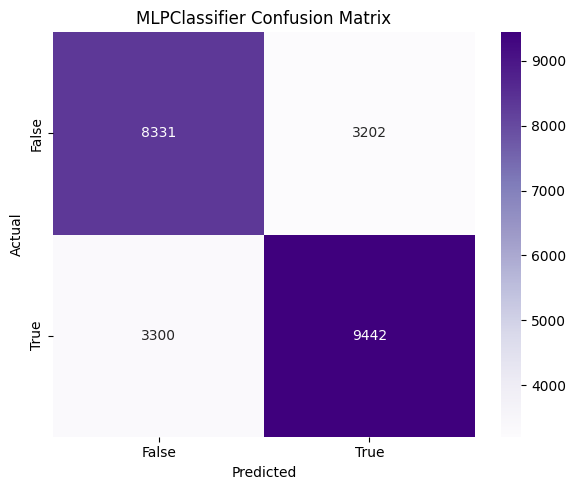

In [ ]:
# I visualize the MLP confusion matrix.

mlp_cm_final = confusion_matrix(
    rf_y_test,
    mlp_pred_final
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    mlp_cm_final,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["False", "True"],
    yticklabels=["False", "True"]
)

plt.title("MLPClassifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

Keras Sequential Neural Network
Training feature shape: (109923, 50)
Testing feature shape: (24275, 50)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,377 (21.00 KB)

 Trainable params: 5,377 (21.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8651 - loss: 0.3121 - val_accuracy: 0.5842 - val_loss: 1.3070
Epoch 2/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9154 - loss: 0.2080 - val_accuracy: 0.6169 - val_loss: 1.2196
Epoch 3/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9264 - loss: 0.1863 - val_accuracy: 0.5907 - val_loss: 1.2906
Epoch 4/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9318 - loss: 0.1728 - val_accuracy: 0.6023 - val_loss: 1.2385
Epoch 5/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9356 - loss: 0.1642 - val_accuracy: 0.5949 - val_loss: 1.2717

Keras Sequential Neural Network Results
Accuracy :  0.7825
Precision:  0.7365
Recall   :  0.9119
F1-Score :  0.8149
ROC-AUC  :  0.8677
PR-AUC   :  0.8444

Classification Report:
              precision    recall  f1-score   support

       False       0.87      0.64      0.74     11533
        True       0.74      0.91      0.81     12742

    accuracy     

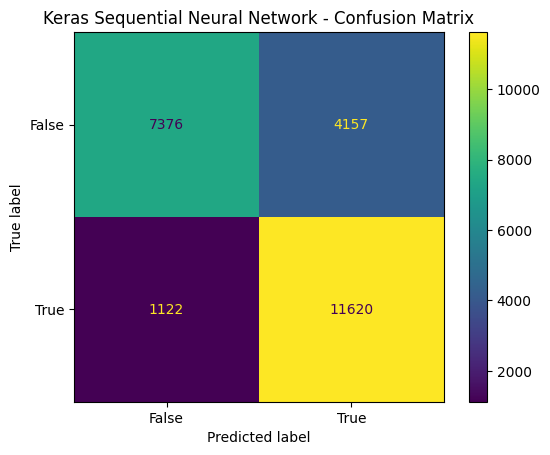

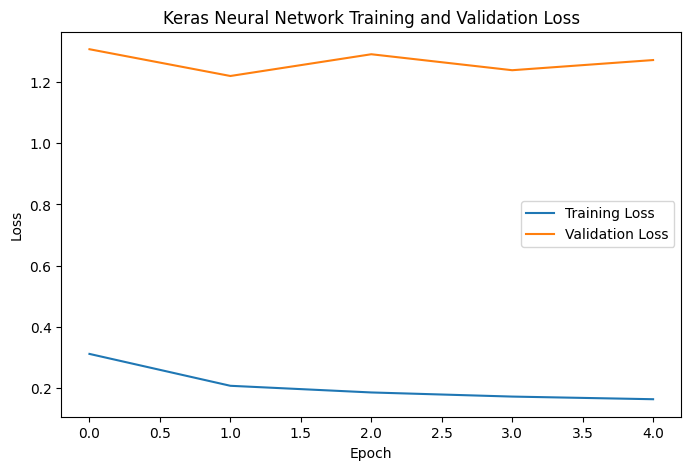

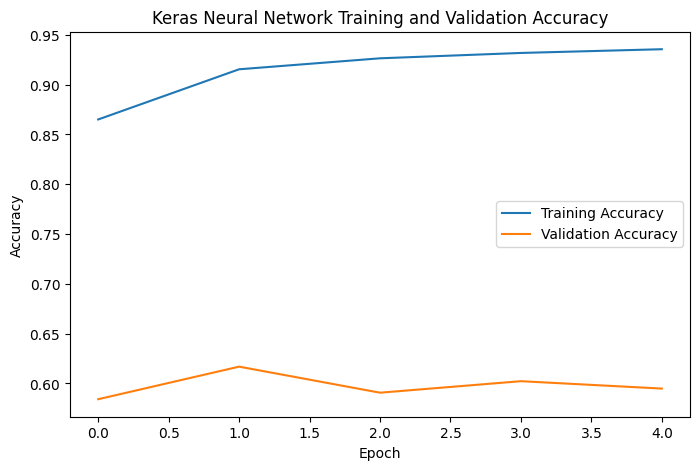

In [ ]:
#Keras Sequential Neural Network
# ============================================================
# TASK 4: INTRODUCTION TO DEEP LEARNING
# KERAS SEQUENTIAL NEURAL NETWORK
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Keras Sequential Neural Network")
print("=" * 50)

# ------------------------------------------------------------
# 1. Scale the SVD features
# ------------------------------------------------------------

keras_scaler_final = StandardScaler()

keras_train_features = keras_scaler_final.fit_transform(
    rf_train_features
)

keras_test_features = keras_scaler_final.transform(
    rf_test_features
)

print("Training feature shape:", keras_train_features.shape)
print("Testing feature shape:", keras_test_features.shape)


# ------------------------------------------------------------
# 2. Create the Sequential Neural Network
# ------------------------------------------------------------

keras_model_final = Sequential([

    Input(shape=(keras_train_features.shape[1],)),

    Dense(64, activation="relu"),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(1, activation="sigmoid")
])

keras_model_final.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

keras_model_final.summary()


# ------------------------------------------------------------
# 3. Early stopping
# ------------------------------------------------------------

keras_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


# ------------------------------------------------------------
# 4. Train the neural network
# ------------------------------------------------------------

keras_history_final = keras_model_final.fit(
    keras_train_features,
    rf_y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=256,
    callbacks=[keras_early_stop],
    verbose=1
)


# ------------------------------------------------------------
# 5. Make predictions
# ------------------------------------------------------------

keras_prob_final = (
    keras_model_final.predict(
        keras_test_features,
        verbose=0
    ).ravel()
)

keras_pred_final = (
    keras_prob_final >= 0.50
).astype(int)


# ------------------------------------------------------------
# 6. Evaluate the model
# ------------------------------------------------------------

keras_accuracy_final = accuracy_score(
    rf_y_test,
    keras_pred_final
)

keras_precision_final = precision_score(
    rf_y_test,
    keras_pred_final,
    zero_division=0
)

keras_recall_final = recall_score(
    rf_y_test,
    keras_pred_final,
    zero_division=0
)

keras_f1_final = f1_score(
    rf_y_test,
    keras_pred_final,
    zero_division=0
)

keras_roc_auc_final = roc_auc_score(
    rf_y_test,
    keras_prob_final
)

keras_pr_auc_final = average_precision_score(
    rf_y_test,
    keras_prob_final
)

print("\nKeras Sequential Neural Network Results")
print("=" * 50)

print(f"Accuracy :  {keras_accuracy_final:.4f}")
print(f"Precision:  {keras_precision_final:.4f}")
print(f"Recall   :  {keras_recall_final:.4f}")
print(f"F1-Score :  {keras_f1_final:.4f}")
print(f"ROC-AUC  :  {keras_roc_auc_final:.4f}")
print(f"PR-AUC   :  {keras_pr_auc_final:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        rf_y_test,
        keras_pred_final,
        target_names=["False", "True"],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 7. Confusion Matrix
# ------------------------------------------------------------

keras_cm_final = confusion_matrix(
    rf_y_test,
    keras_pred_final
)

ConfusionMatrixDisplay(
    confusion_matrix=keras_cm_final,
    display_labels=["False", "True"]
).plot()

plt.title("Keras Sequential Neural Network - Confusion Matrix")
plt.show()


# ------------------------------------------------------------
# 8. Training and validation loss
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    keras_history_final.history["loss"],
    label="Training Loss"
)

plt.plot(
    keras_history_final.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Keras Neural Network Training and Validation Loss")
plt.legend()
plt.show()


# ------------------------------------------------------------
# 9. Training and validation accuracy
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    keras_history_final.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    keras_history_final.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Keras Neural Network Training and Validation Accuracy")
plt.legend()
plt.show()

## Model Comparison

I now compare Random Forest and MLPClassifier using the same test data and the same reduced TF-IDF representation. This makes the comparison easier to understand because both models receive the same type of input.

In [ ]:
# I compare the two models using the same test dataset.

comparison_final = pd.DataFrame({
    "Model": [
        "Random Forest",
        "MLPClassifier"
    ],
    "Accuracy": [
        rf_accuracy_final,
        mlp_accuracy_final
    ],
    "Precision": [
        rf_precision_final,
        mlp_precision_final
    ],
    "Recall": [
        rf_recall_final,
        mlp_recall_final
    ],
    "F1-Score": [
        rf_f1_final,
        mlp_f1_final
    ],
    "ROC-AUC": [
        rf_auc_final,
        mlp_auc_final
    ],
    "PR-AUC": [
        rf_pr_auc_final,
        mlp_pr_auc_final
    ],
    "Training Time (sec)": [
        rf_train_time,
        mlp_train_time
    ]
})

display(
    comparison_final.round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Training Time (sec)
0,Random Forest,0.7872,0.7517,0.8879,0.8141,0.8528,0.8447,122.382
1,MLPClassifier,0.7322,0.7468,0.7410,0.7439,0.8157,0.8190,17.148


In [ ]:
print("\nFINAL MODEL COMPARISON")
print("=" * 60)

print(
    f"Random Forest Accuracy : {accuracy_score(rf_y_test, rf_pred_final):.4f}"
)

print(
    f"Keras Accuracy         : {keras_accuracy_final:.4f}"
)

print(
    f"\nRandom Forest F1       : "
    f"{f1_score(rf_y_test, rf_pred_final):.4f}"
)

print(
    f"Keras F1               : "
    f"{keras_f1_final:.4f}"
)

print(
    f"\nRandom Forest ROC-AUC  : "
    f"{roc_auc_score(rf_y_test, rf_prob_final):.4f}"
)

print(
    f"Keras ROC-AUC          : "
    f"{keras_roc_auc_final:.4f}"
)


FINAL MODEL COMPARISON
Random Forest Accuracy : 0.7872
Keras Accuracy         : 0.7825

Random Forest F1       : 0.8141
Keras F1               : 0.8149

Random Forest ROC-AUC  : 0.8528
Keras ROC-AUC          : 0.8677


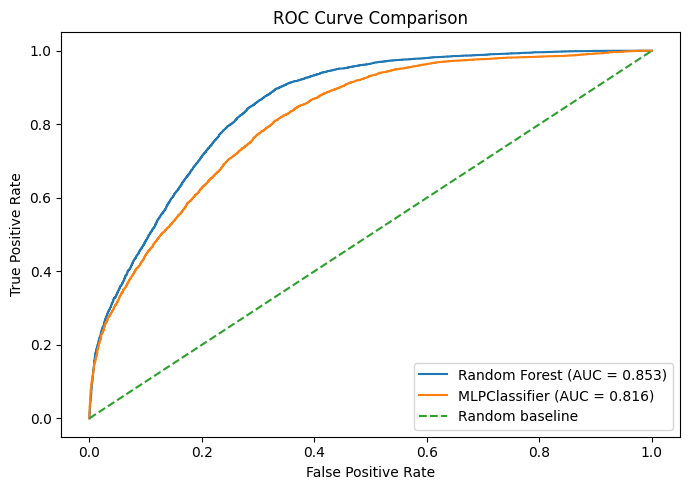

In [ ]:
from sklearn.metrics import roc_curve

# I compare the ROC curves of both models.

rf_fpr, rf_tpr, _ = roc_curve(
    rf_y_test,
    rf_prob_final
)

mlp_fpr, mlp_tpr, _ = roc_curve(
    rf_y_test,
    mlp_prob_final
)

plt.figure(figsize=(7, 5))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc_final:.3f})"
)

plt.plot(
    mlp_fpr,
    mlp_tpr,
    label=f"MLPClassifier (AUC = {mlp_auc_final:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random baseline"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()
plt.show()

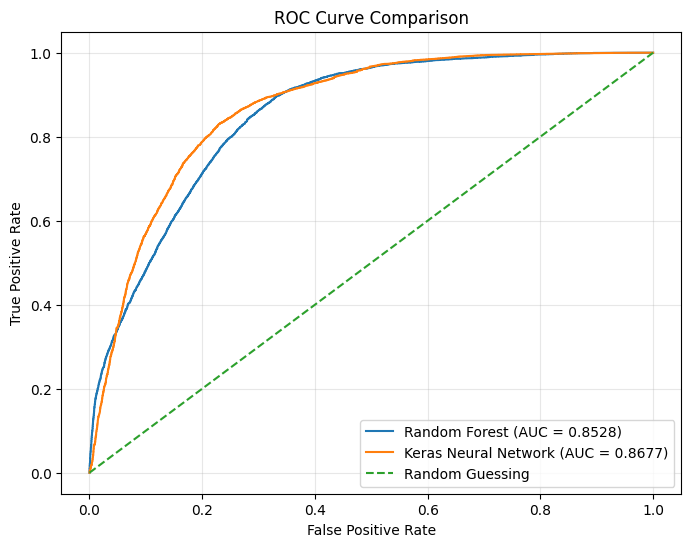

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Random Forest ROC curve
rf_fpr, rf_tpr, _ = roc_curve(
    rf_y_test,
    rf_prob_final
)

rf_auc = roc_auc_score(
    rf_y_test,
    rf_prob_final
)

# Keras ROC curve
keras_fpr, keras_tpr, _ = roc_curve(
    rf_y_test,
    keras_prob_final
)

keras_auc = roc_auc_score(
    rf_y_test,
    keras_prob_final
)

# Plot both ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.4f})"
)

plt.plot(
    keras_fpr,
    keras_tpr,
    label=f"Keras Neural Network (AUC = {keras_auc:.4f})"
)

# Random guessing line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guessing"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Task 5 — Improved Deep Learning Model with Hyperparameter Tuning

In this section, I improve the existing Keras neural network by tuning its learning rate, batch size, and training epochs. I also use dropout and L2 regularization to reduce overfitting.

Early stopping monitors validation loss and restores the best model weights, while learning-rate reduction helps the model continue learning when progress slows. The aim is to improve generalization and achieve better classification performance on unseen data.

**Create a grouped validation dataset**

We split the original training data into training and validation subsets based on the statement column. This prevents tweets from the same statement from appearing in both subsets. Stratification helps preserve the class distribution.

In [ ]:
# ============================================================
# 1. CREATE TRAINING AND VALIDATION DATA
# ============================================================

from sklearn.model_selection import train_test_split
import numpy as np

# Create one label per statement for stratified splitting
statement_labels_improved = (
    rf_train_df.groupby("statement")["BinaryNumTarget"]
    .first()
    .reset_index()
)

# Split statement groups into training and validation groups
train_statements_improved, val_statements_improved = train_test_split(
    statement_labels_improved,
    test_size=0.20,
    random_state=42,
    stratify=statement_labels_improved["BinaryNumTarget"]
)

# Convert statement lists to sets
train_statement_set_improved = set(
    train_statements_improved["statement"]
)

val_statement_set_improved = set(
    val_statements_improved["statement"]
)

# Select corresponding tweet rows
train_df_improved = rf_train_df[
    rf_train_df["statement"].isin(train_statement_set_improved)
].copy()

val_df_improved = rf_train_df[
    rf_train_df["statement"].isin(val_statement_set_improved)
].copy()

# Extract features and labels
X_train_improved = rf_train_features[
    rf_train_df["statement"].isin(train_statement_set_improved)
]

X_val_improved = rf_train_features[
    rf_train_df["statement"].isin(val_statement_set_improved)
]

y_train_improved = train_df_improved["BinaryNumTarget"].astype(int)
y_val_improved = val_df_improved["BinaryNumTarget"].astype(int)

print("Training samples:", X_train_improved.shape[0])
print("Validation samples:", X_val_improved.shape[0])
print("Training class distribution:")
print(y_train_improved.value_counts(normalize=True).round(3))

print("\nValidation class distribution:")
print(y_val_improved.value_counts(normalize=True).round(3))

Training samples: 90889
Validation samples: 19034
Training class distribution:
BinaryNumTarget
1    0.523
0    0.477
Name: proportion, dtype: float64

Validation class distribution:
BinaryNumTarget
0    0.545
1    0.455
Name: proportion, dtype: float64


**Cell 3 — Feature scaling**

Feature scaling standardizes the numerical SVD features. The scaler is fitted only on the training subset and then applied to the validation and test sets, preventing information from leaking from the evaluation data into training.

In [ ]:
# ============================================================
# 2. FEATURE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

improved_scaler_final = StandardScaler()

# Fit on training subset only
X_train_improved_scaled = improved_scaler_final.fit_transform(
    X_train_improved
)

# Transform validation and test subsets
X_val_improved_scaled = improved_scaler_final.transform(
    X_val_improved
)

X_test_improved_scaled = improved_scaler_final.transform(
    rf_test_features
)

print("Training features:", X_train_improved_scaled.shape)
print("Validation features:", X_val_improved_scaled.shape)
print("Testing features:", X_test_improved_scaled.shape)

Training features: (90889, 50)
Validation features: (19034, 50)
Testing features: (24275, 50)


Cell 4 **— Build the improved neural network**

The improved model contains three hidden layers with 128, 64, and 32 neurons. Dropout and L2 regularization are added to reduce overfitting, while the final sigmoid layer produces a probability for binary classification.

In [ ]:
# ============================================================
# 3. BUILD IMPROVED KERAS MODEL
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.regularizers import l2

improved_keras_model_final = Sequential([

    Input(shape=(X_train_improved_scaled.shape[1],)),

    Dense(128, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.40),

    Dense(64, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.30),

    Dense(32, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.20),

    Dense(1, activation="sigmoid")
])

improved_keras_model_final.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │         6,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,897 (66.00 KB)

 Trainable params: 16,897 (66.00 KB)

 Non-trainable params: 0 (0.00 B)

**Cell 5 — Configure learning rate and optimizer**

Adam is used to optimize the model weights. We start with a learning rate of 0.0005, which is lower than the original default of 0.001. A smaller learning rate may provide more stable updates during training.

In [ ]:
# ============================================================
# 4. COMPILE MODEL
# ============================================================

from tensorflow.keras.optimizers import Adam

learning_rate_improved = 0.0005

improved_keras_model_final.compile(
    optimizer=Adam(learning_rate=learning_rate_improved),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Learning rate:", learning_rate_improved)
print("Optimizer: Adam")
print("Loss: Binary Crossentropy")

Learning rate: 0.0005
Optimizer: Adam
Loss: Binary Crossentropy


**Cell 6 — Early Stopping and Learning-Rate Callbacks**

During training, I use two callbacks to help the model train more efficiently and avoid overfitting. Early Stopping monitors the validation loss and stops training if it does not improve for 8 consecutive epochs, while restoring the best weights achieved during training. ReduceLROnPlateau reduces the learning rate when the model's performance stops improving, allowing it to make smaller and more careful updates to its weights. Together, these callbacks help the model find better results without continuing unnecessary training.

In [ ]:
# ============================================================
# 5. TRAINING CALLBACKS
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

improved_early_stop_final = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

improved_reduce_lr_final = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

print("Callbacks configured successfully.")

Callbacks configured successfully.


**Cell 7 — Train the improved model**

The maximum number of epochs is increased to 100 to give the model enough opportunities to learn. Early stopping ensures that training ends automatically when validation performance stops improving.

A batch size of 128 is used to balance learning stability and computational efficiency.

In [ ]:
# ============================================================
# 6. TRAIN IMPROVED MODEL
# ============================================================

improved_keras_history_final = improved_keras_model_final.fit(
    X_train_improved_scaled,
    y_train_improved,

    validation_data=(
        X_val_improved_scaled,
        y_val_improved
    ),

    epochs=100,
    batch_size=128,

    callbacks=[
        improved_early_stop_final,
        improved_reduce_lr_final
    ],

    verbose=1
)

Epoch 1/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8275 - loss: 0.5280 - val_accuracy: 0.8112 - val_loss: 0.6587 - learning_rate: 5.0000e-04
Epoch 2/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8978 - loss: 0.3509 - val_accuracy: 0.8052 - val_loss: 0.6690 - learning_rate: 5.0000e-04
Epoch 3/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9120 - loss: 0.2884 - val_accuracy: 0.7949 - val_loss: 0.7446 - learning_rate: 5.0000e-04
Epoch 4/100
707/711 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9201 - loss: 0.2581
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9218 - loss: 0.2511 - val_accuracy: 0.7735 - val_loss: 0.7823 - learning_rate: 5.0000e-04
Epoch 5/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9274 - loss: 0.2292 - val_accuracy: 0.7649 - val_loss: 0.7962 - learning_rate: 2.5000e-04
Epoch 6/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy:

**Cell 8 — Plot accuracy**

This graph compares training and validation accuracy over the epochs. It helps us check whether the model is improving and whether it is beginning to overfit the training data.

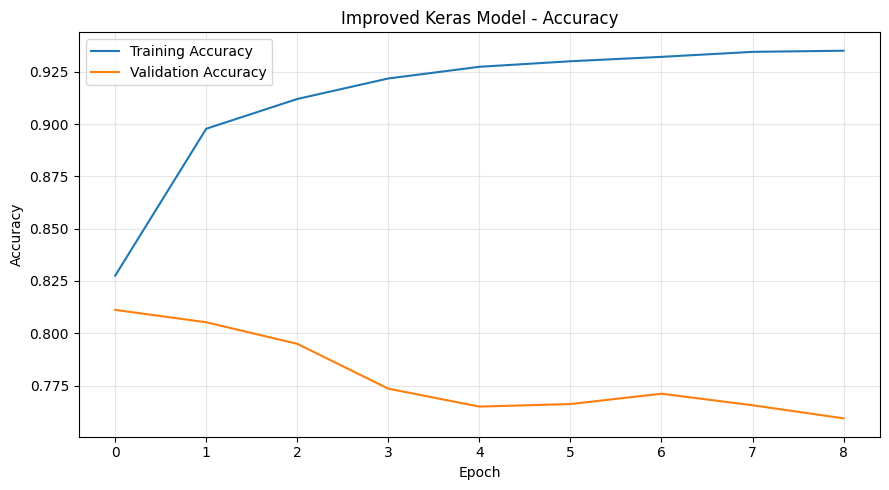

In [ ]:
# ============================================================
# 7. PLOT TRAINING AND VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    improved_keras_history_final.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    improved_keras_history_final.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Improved Keras Model - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Cell 9 — Plot loss**

The loss graph shows how prediction error changes during training. A decreasing validation loss indicates that the model is improving on unseen validation data. If validation loss begins rising while training loss continues falling, overfitting may be occurring.

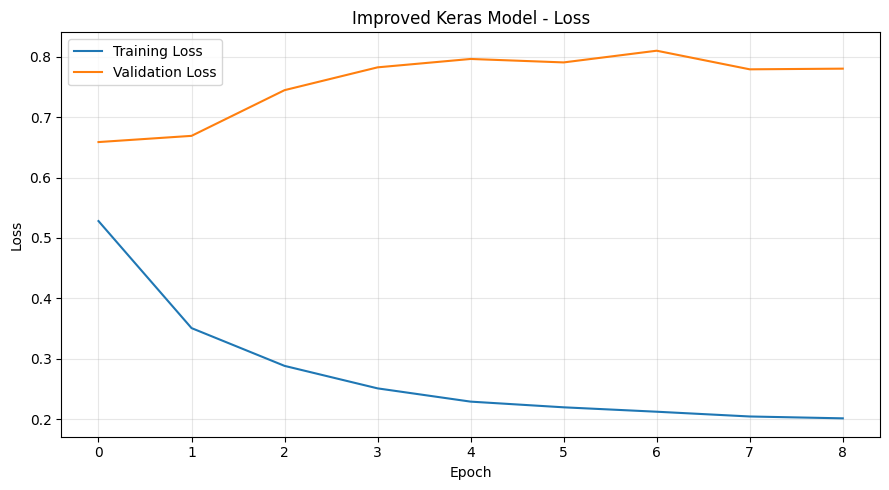

In [ ]:
# ============================================================
# 8. PLOT TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    improved_keras_history_final.history["loss"],
    label="Training Loss"
)

plt.plot(
    improved_keras_history_final.history["val_loss"],
    label="Validation Loss"
)

plt.title("Improved Keras Model - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Cell 10 — Evaluate on the test set**

The test dataset is used only after model training and validation are complete. We calculate several metrics instead of relying only on accuracy, since accuracy alone may not fully describe threat-classification performance.

In [ ]:
# ============================================================
# 9. FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# Predict probabilities
improved_keras_prob_final = (
    improved_keras_model_final
    .predict(X_test_improved_scaled, verbose=0)
    .ravel()
)

# Convert probabilities to binary classes
improved_keras_pred_final = (
    improved_keras_prob_final >= 0.50
).astype(int)

# Calculate evaluation metrics
improved_keras_accuracy_final = accuracy_score(
    rf_y_test, improved_keras_pred_final
)

improved_keras_precision_final = precision_score(
    rf_y_test, improved_keras_pred_final, zero_division=0
)

improved_keras_recall_final = recall_score(
    rf_y_test, improved_keras_pred_final, zero_division=0
)

improved_keras_f1_final = f1_score(
    rf_y_test, improved_keras_pred_final, zero_division=0
)

improved_keras_roc_auc_final = roc_auc_score(
    rf_y_test, improved_keras_prob_final
)

improved_keras_pr_auc_final = average_precision_score(
    rf_y_test, improved_keras_prob_final
)

print("=" * 55)
print("IMPROVED KERAS NEURAL NETWORK RESULTS")
print("=" * 55)

print(f"Accuracy  : {improved_keras_accuracy_final:.4f}")
print(f"Precision : {improved_keras_precision_final:.4f}")
print(f"Recall   : {improved_keras_recall_final:.4f}")
print(f"F1-Score : {improved_keras_f1_final:.4f}")
print(f"ROC-AUC  : {improved_keras_roc_auc_final:.4f}")
print(f"PR-AUC   : {improved_keras_pr_auc_final:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    rf_y_test,
    improved_keras_pred_final,
    target_names=["False", "True"],
    zero_division=0
))

IMPROVED KERAS NEURAL NETWORK RESULTS
Accuracy  : 0.7803
Precision : 0.7711
Recall   : 0.8270
F1-Score : 0.7981
ROC-AUC  : 0.8508
PR-AUC   : 0.8338

Classification Report:

              precision    recall  f1-score   support

       False       0.79      0.73      0.76     11533
        True       0.77      0.83      0.80     12742

    accuracy                           0.78     24275
   macro avg       0.78      0.78      0.78     24275
weighted avg       0.78      0.78      0.78     24275



**Cell 11 — Improved model confusion matrix**

The confusion matrix displays correct and incorrect predictions for both classes. It helps us understand whether the improved model is correctly identifying threat-related and non-threat-related samples.

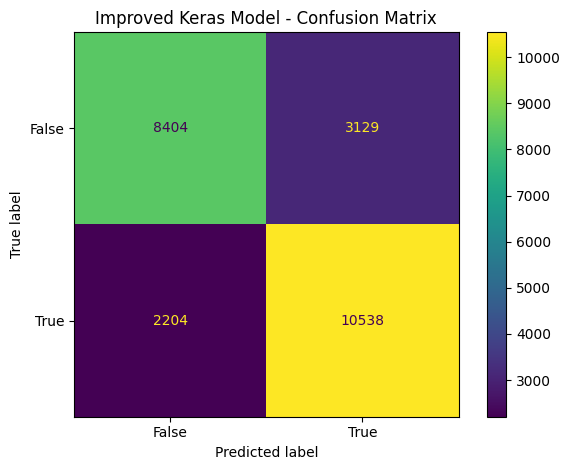

In [ ]:
# ============================================================
# 10. IMPROVED MODEL CONFUSION MATRIX
# ============================================================

improved_keras_cm_final = confusion_matrix(
    rf_y_test,
    improved_keras_pred_final
)

ConfusionMatrixDisplay(
    confusion_matrix=improved_keras_cm_final,
    display_labels=["False", "True"]
).plot()

plt.title("Improved Keras Model - Confusion Matrix")
plt.tight_layout()
plt.show()

**Cell 12 — Compare the original and improved models**

This table compares your original models with the improved Keras model using the same test dataset. Sorting by accuracy makes it easy to identify which model achieved the highest result.

In [ ]:
# ============================================================
# 11. FINAL MODEL COMPARISON
# ============================================================

comparison_improved_final = pd.DataFrame({
    "Model": [
        "Random Forest",
        "MLPClassifier",
        "Original Keras",
        "Improved Keras"
    ],

    "Accuracy": [
        rf_accuracy_final,
        mlp_accuracy_final,
        keras_accuracy_final,
        improved_keras_accuracy_final
    ],

    "Precision": [
        rf_precision_final,
        mlp_precision_final,
        keras_precision_final,
        improved_keras_precision_final
    ],

    "Recall": [
        rf_recall_final,
        mlp_recall_final,
        keras_recall_final,
        improved_keras_recall_final
    ],

    "F1-Score": [
        rf_f1_final,
        mlp_f1_final,
        keras_f1_final,
        improved_keras_f1_final
    ],

    "ROC-AUC": [
        rf_auc_final,
        mlp_auc_final,
        keras_roc_auc_final,
        improved_keras_roc_auc_final
    ],

    "PR-AUC": [
        rf_pr_auc_final,
        mlp_pr_auc_final,
        keras_pr_auc_final,
        improved_keras_pr_auc_final
    ]
})

comparison_improved_final = comparison_improved_final.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(comparison_improved_final.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest,0.7872,0.7517,0.8879,0.8141,0.8528,0.8447
1,Original Keras,0.7825,0.7365,0.9119,0.8149,0.8677,0.8444
2,Improved Keras,0.7803,0.7711,0.8270,0.7981,0.8508,0.8338
3,MLPClassifier,0.7322,0.7468,0.7410,0.7439,0.8157,0.8190


**Cell 13 — Identify the best model**

This final cell automatically identifies the model with the highest test accuracy and displays its accuracy, F1-score, and ROC-AUC.

In [ ]:
# ============================================================
# 12. IDENTIFY BEST MODEL
# ============================================================

best_model_improved_final = comparison_improved_final.iloc[0]

print("=" * 55)
print("BEST PERFORMING MODEL")
print("=" * 55)

print("Model:", best_model_improved_final["Model"])
print(f"Accuracy : {best_model_improved_final['Accuracy']:.4f}")
print(f"F1-Score: {best_model_improved_final['F1-Score']:.4f}")
print(f"ROC-AUC : {best_model_improved_final['ROC-AUC']:.4f}")

BEST PERFORMING MODEL
Model: Random Forest
Accuracy : 0.7872
F1-Score: 0.8141
ROC-AUC : 0.8528


## My Conclusion

In this mini-project, I completed all four tasks in sequence.

For Task 1, I prepared the Colab environment and loaded the provided dataset.

For Task 2, I performed EDA and data cleaning. I checked the dataset structure, target distribution, missing values, duplicates, and social-media activity patterns.

For Task 3, I used Random Forest for the machine-learning classification task. I converted tweet text into TF-IDF features and reduced the feature size using TruncatedSVD.

For Task 4, I used both **MLPClassifier and a Keras Sequential Neural Network** as my basic deep-learning models. I trained both models using the same processed features and the same statement-level test split to ensure a fair and consistent comparison. I also compared their performance using accuracy, precision, recall, F1-score, and ROC-AUC.

Finally, I compared both models using accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, confusion matrices, and training time.